# Milestone 3 - Neural Network & CNNs

In [19]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import os
import random
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score
from tqdm import tqdm
import wandb

random.seed(42)
np.random.seed(42)

## 1) Audio to Mel-Spectrogram

In [20]:
audio_path = './messy_mashup/genres_stems/disco/disco.00098/vocals.wav'

y, sr = librosa.load(audio_path)
mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, hop_length=512)
mel_spectrogram_db = librosa.power_to_db(mel_spectrogram, ref=np.max)
mel_spectrogram_db.shape

(128, 1293)

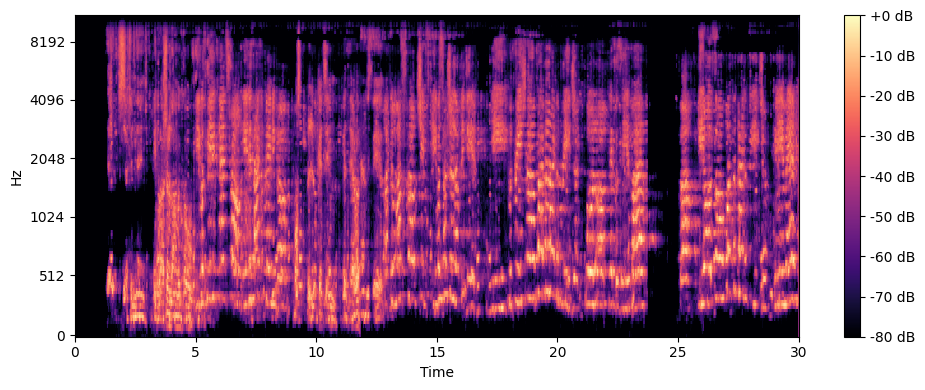

In [21]:
plt.figure(figsize=(10, 4))
librosa.display.specshow(mel_spectrogram_db, sr=sr, hop_length=512, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.tight_layout()
plt.show()

## 2) Creating Spectrogram Dataset

In [22]:
dataset_path = './messy_mashup/genres_stems'
noise_path = './messy_mashup/ESC-50-master/audio'
noise_files = [os.path.join(noise_path, f) for f in os.listdir(noise_path) if f.endswith('.wav')]

X_photos = []
y_labels = []
FIXED_WIDTH = 1293

genres = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]

for genre in tqdm(genres, desc="Processing Genres"):
    genre_path = os.path.join(dataset_path, genre)

    for song_folder in os.listdir(genre_path):
        song_path = os.path.join(genre_path, song_folder)

        if os.path.exists(os.path.join(song_path, 'vocals.wav')):
            try:
                v, sr = librosa.load(os.path.join(song_path, 'vocals.wav'), sr=22050)
                d, _ = librosa.load(os.path.join(song_path, 'drums.wav'), sr=22050)
                b, _ = librosa.load(os.path.join(song_path, 'bass.wav'), sr=22050)
                o, _ = librosa.load(os.path.join(song_path, 'other.wav'), sr=22050)

                min_len = min(len(v), len(d), len(b), len(o))
                v, d, b, o = v[:min_len], d[:min_len], b[:min_len], o[:min_len]
                clean_mix = v + d + b + o

                noise_file = random.choice(noise_files)
                noise, _ = librosa.load(noise_file, sr=22050)

                if len(noise) < len(clean_mix):
                    noise = np.tile(noise, int(np.ceil(len(clean_mix) / len(noise))))
                noise = noise[:len(clean_mix)]

                messy_audio = clean_mix + (noise * 0.5)
                messy_audio = messy_audio / np.max(np.abs(messy_audio))

                mel_spec = librosa.feature.melspectrogram(y=messy_audio, sr=sr, n_mels=128, hop_length=512)
                mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

                if mel_spec_db.shape[1] > FIXED_WIDTH:
                    mel_spec_db = mel_spec_db[:, :FIXED_WIDTH]
                elif mel_spec_db.shape[1] < FIXED_WIDTH:
                    pad_width = FIXED_WIDTH - mel_spec_db.shape[1]
                    mel_spec_db = np.pad(mel_spec_db, ((0, 0), (0, pad_width)), mode='constant')

                X_photos.append(mel_spec_db)
                y_labels.append(genre)
            except:
                pass

X_array = np.array(X_photos)
y_array = np.array(y_labels)

np.save('X_spectrograms_full.npy', X_array)
np.save('y_labels_full.npy', y_array)

print(f"Total samples: {len(X_array)}, Shape: {X_array.shape}")

Processing Genres: 100%|██████████| 10/10 [10:36<00:00, 63.65s/it]


Total samples: 1000, Shape: (1000, 128, 1293)


## 3) PyTorch DataLoader

In [23]:
X = np.load('X_spectrograms_full.npy')
y = np.load('y_labels_full.npy')

X = np.expand_dims(X, axis=1)

enc = LabelEncoder()
y = enc.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [24]:
class AudioDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]

In [25]:
train_dataset = AudioDataset(X_train, y_train)
val_dataset = AudioDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [26]:
for batch_X, batch_y in train_loader:
    print(batch_X.shape, batch_y.shape)
    break

torch.Size([32, 1, 128, 1293]) torch.Size([32])


## 4) CNN Model

In [27]:
class AudioCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(AudioCNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 8))

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 4 * 8, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))

        x = self.adaptive_pool(x)
        x = self.flatten(x)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [28]:
model = AudioCNN(num_classes=10)
dummy = torch.randn(32, 1, 128, 1293)
print(model(dummy).shape)

torch.Size([32, 10])


## 5) Training with W&B Logging

In [29]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = AudioCNN(num_classes=10).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)


# wandb.login(key=os.environ.get('key'))
# run = wandb.init(
#     project="24f2007692-t12026",
#     name='cnn-spectogram-training-02',
#     config={
#         "learning_rate": 0.0005,
#         "epochs": 40,
#         "batch_size": 32,
#         'model': 'AudioCNN',
#         "architecture": "AudioCNN/CustomCNN",
#     }
# )

## 6) Train & Evaluate

In [30]:
EPOCHS = 45

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for features, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        features, labels = features.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(features)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)

    model.eval()
    all_pred, all_labels = [], []

    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            outputs = model(features)
            _, predicted = torch.max(outputs, 1)

            all_pred.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    f1 = f1_score(all_labels, all_pred, average="macro", zero_division=0)
    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_train_loss:.4f} - Val F1: {f1:.4f}")

    # wandb.log({"epoch": epoch+1, "train_loss": avg_train_loss, "macro_f1": f1})

print("Training complete!")
# wandb.finish()

Epoch 1/45:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 1/45: 100%|██████████| 25/25 [00:03<00:00,  7.56it/s]


Epoch [1/45] - Loss: 2.3460 - Val F1: 0.0312


Epoch 2/45: 100%|██████████| 25/25 [00:02<00:00, 10.44it/s]


Epoch [2/45] - Loss: 2.2949 - Val F1: 0.0182


Epoch 3/45: 100%|██████████| 25/25 [00:02<00:00, 10.25it/s]


... (81 outputs left out)

Epoch 44/45: 100%|██████████| 25/25 [00:02<00:00, 10.71it/s]


Epoch [44/45] - Loss: 0.5417 - Val F1: 0.6623


Epoch 45/45: 100%|██████████| 25/25 [00:02<00:00, 10.57it/s]


Epoch [45/45] - Loss: 0.4920 - Val F1: 0.6475
Training complete!


## 7) Test Predictions

In [32]:
test_csv = './messy_mashup/test.csv'
test_folder = './messy_mashup/'

df_test = pd.read_csv(test_csv)

test_files = df_test['filename'].tolist()
id_list = df_test['id'].tolist()

model.eval()

fixed_width = 1293
predictions = []

with torch.no_grad():
    for file in tqdm(test_files, desc="Predicting"):
        file_path = os.path.join(test_folder, file)
        try:
            y, sr = librosa.load(file_path, sr=22050)

            mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, hop_length=512)
            mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

            if mel_spec_db.shape[1] > fixed_width:
                mel_spec_db = mel_spec_db[:, :fixed_width]
            else:
                pad_width = fixed_width - mel_spec_db.shape[1]
                mel_spec_db = np.pad(mel_spec_db, ((0, 0), (0, pad_width)), mode='constant')

            tensor_audio = torch.tensor(mel_spec_db, dtype=torch.float32)
            tensor_audio = tensor_audio.unsqueeze(0).unsqueeze(0).to(device)

            output = model(tensor_audio)
            predicted_class_idx = torch.argmax(output, dim=1).item()
            predicted_genre = enc.inverse_transform([predicted_class_idx])[0]

            predictions.append(predicted_genre)
        except Exception as e:
            print(e)
            predictions.append('pop')

df_sub = pd.DataFrame({'id': id_list, 'genre': predictions})
df_sub.to_csv('submission.csv', index=False)
print(df_sub.head())

Predicting:   0%|          | 0/3020 [00:00<?, ?it/s]

Predicting: 100%|██████████| 3020/3020 [08:04<00:00,  6.23it/s]


   id      genre
0   1     hiphop
1   2  classical
2   3      disco
3   4      blues
4   5      blues
